In [7]:
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from torchvision.models import MobileNet_V2_Weights
import matplotlib.pyplot as plt
import time
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

torch.manual_seed(42)

# PART A

In [8]:
transform = transforms.ToTensor()

full_train = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=transform
)

train_size = int(0.8 * len(full_train))
val_size = len(full_train) - train_size
train_data, val_data = random_split(full_train, [train_size, val_size])

test_data = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=transform
)

batch_size = 64
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_data,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_data,  batch_size=batch_size, shuffle=False)


print(f"Train: {len(train_data)}, Val: {len(val_data)}, Test: {len(test_data)}")

image, label = train_data[0]
print("Image shape:", image.shape)

Train: 40000, Val: 10000, Test: 10000
Image shape: torch.Size([3, 32, 32])


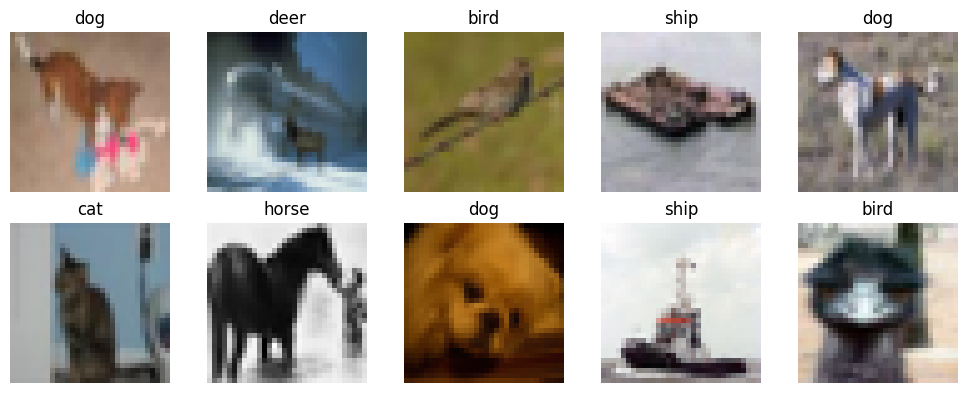

In [9]:
# CIFAR-10 class names
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

# extract and show a few images (MNIST-style)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax in axes.flat:
    image, label = train_data[torch.randint(0, len(train_data), (1,)).item()]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(classes[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.BatchNorm2d(128),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Flatten(),
    nn.Linear(128 * 4 * 4, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

print(model)
print('Device:', device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=2048, out_features=128, bias=True)
  (14): ReLU()
  (15): Linear(in_features=128, out_features=10, bias=True)
)
Device: cpu


In [11]:
# Helper for evaluation
def get_loss_and_acc(model, loader):
    model.eval()
    total_loss = 0
    y_true, y_pred = [], []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            logits = model(X_batch)
            total_loss += loss_fn(logits, y_batch.to(device)).item()
            preds = logits.argmax(dim=1)
            y_true.extend(y_batch.numpy())
            y_pred.extend(preds.cpu().numpy())
    avg_loss = total_loss / len(loader)
    acc = (torch.tensor(y_true) == torch.tensor(y_pred)).float().mean().item()
    return avg_loss, acc

In [13]:
epochs = 5
train_losses, val_losses = [], []
train_accs, val_accs = [], []

start = time.time()

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model(X_batch)
        loss = loss_fn(logits, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    train_losses.append(total_loss / len(train_loader))
    val_loss, val_acc = get_loss_and_acc(model, val_loader)
    train_acc = get_loss_and_acc(model, train_loader)[1]

    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}: train loss={train_losses[-1]:.4f}, val loss={val_loss:.4f}, "
          f"train acc={train_acc:.1%}, val acc={val_acc:.1%}")

elapsed = time.time() - start
print(f"\nTraining time: {elapsed:.1f} seconds")

Epoch 1: train loss=1.1984, val loss=1.0526, train acc=63.2%, val acc=61.7%
Epoch 2: train loss=0.8584, val loss=0.9488, train acc=69.9%, val acc=67.1%
Epoch 3: train loss=0.7297, val loss=0.8254, train acc=76.0%, val acc=70.9%
Epoch 4: train loss=0.6297, val loss=1.0469, train acc=69.6%, val acc=64.9%
Epoch 5: train loss=0.5525, val loss=1.0437, train acc=71.3%, val acc=65.9%

Training time: 551.2 seconds


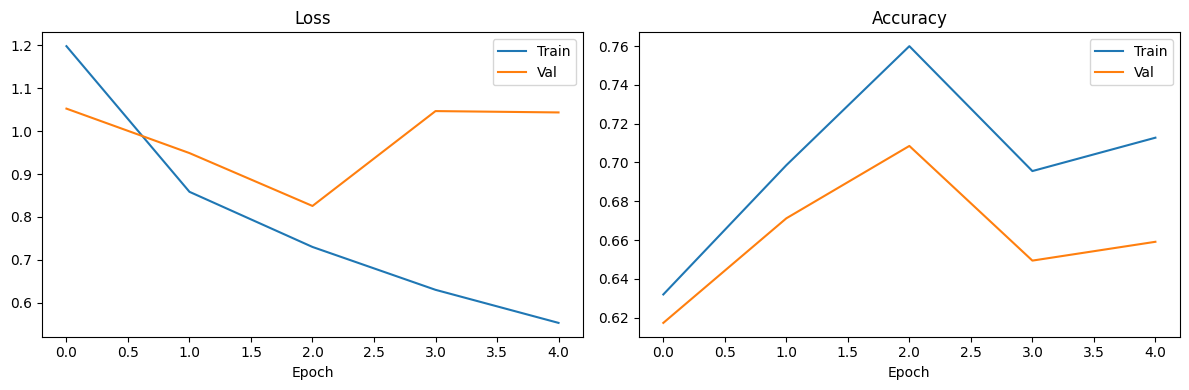

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses, label='Train')
ax1.plot(val_losses, label='Val')
ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(train_accs, label='Train')
ax2.plot(val_accs, label='Val')
ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.legend()

plt.tight_layout()
plt.show()

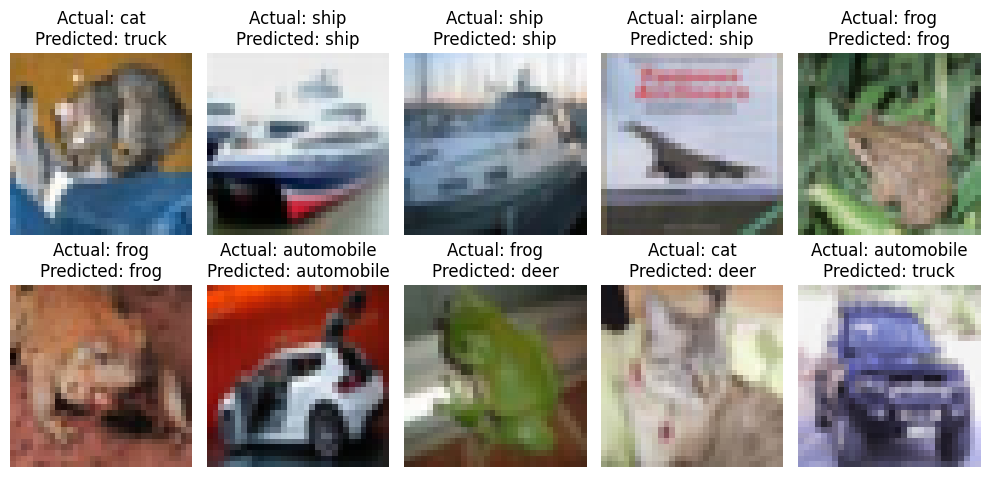

In [15]:
images, labels = next(iter(test_loader))
model.eval()

with torch.no_grad():
    predictions = model(images.to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].permute(1, 2, 0))
    ax.set_title(
        f"Actual: {classes[labels[i]]}\n"
        f"Predicted: {classes[predictions[i]]}"
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

# PART B

In [16]:
augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.1),
    transforms.ToTensor()
])

eval_transform = transforms.ToTensor()

In [17]:
torch.manual_seed(42)

full_train_aug = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=augmentation
)

# same 80/20 split
train_data_aug, val_data_aug = random_split(full_train_aug, [train_size, val_size])

# validation uses the non-augmented transform
val_data_aug.dataset.transform = eval_transform

train_loader_aug = DataLoader(train_data_aug, batch_size=64, shuffle=True)
val_loader_aug   = DataLoader(val_data_aug,   batch_size=64, shuffle=False)

print(f"Augmented train: {len(train_data_aug)}, Val: {len(val_data_aug)}")

Augmented train: 40000, Val: 10000


In [18]:
model_aug = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.BatchNorm2d(128),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Flatten(),
    nn.Linear(128 * 4 * 4, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

optimizer_aug = torch.optim.Adam(model_aug.parameters(), lr=0.001)

In [19]:
epochs = 5
train_losses_aug, val_losses_aug = [], []
train_accs_aug, val_accs_aug = [], []

start = time.time()

for epoch in range(epochs):
    model_aug.train()
    total_loss = 0
    for X_batch, y_batch in train_loader_aug:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model_aug(X_batch)
        loss = loss_fn(logits, y_batch)
        optimizer_aug.zero_grad()
        loss.backward()
        optimizer_aug.step()
        total_loss += loss.item()

    train_losses_aug.append(total_loss / len(train_loader_aug))
    val_loss, val_acc = get_loss_and_acc(model_aug, val_loader_aug)
    train_acc = get_loss_and_acc(model_aug, train_loader_aug)[1]

    val_losses_aug.append(val_loss)
    train_accs_aug.append(train_acc)
    val_accs_aug.append(val_acc)

    print(f"Epoch {epoch+1}: train loss={train_losses_aug[-1]:.4f}, val loss={val_loss:.4f}, "
          f"train acc={train_acc:.1%}, val acc={val_acc:.1%}")

elapsed_aug = time.time() - start
print(f"\nAugmented training time: {elapsed_aug:.1f} seconds")

Epoch 1: train loss=1.2265, val loss=1.0131, train acc=65.8%, val acc=63.9%
Epoch 2: train loss=0.8673, val loss=0.9499, train acc=69.0%, val acc=66.3%
Epoch 3: train loss=0.7317, val loss=0.8484, train acc=74.5%, val acc=69.9%
Epoch 4: train loss=0.6302, val loss=0.9142, train acc=74.8%, val acc=69.7%
Epoch 5: train loss=0.5502, val loss=0.8404, train acc=79.3%, val acc=71.9%

Augmented training time: 552.8 seconds


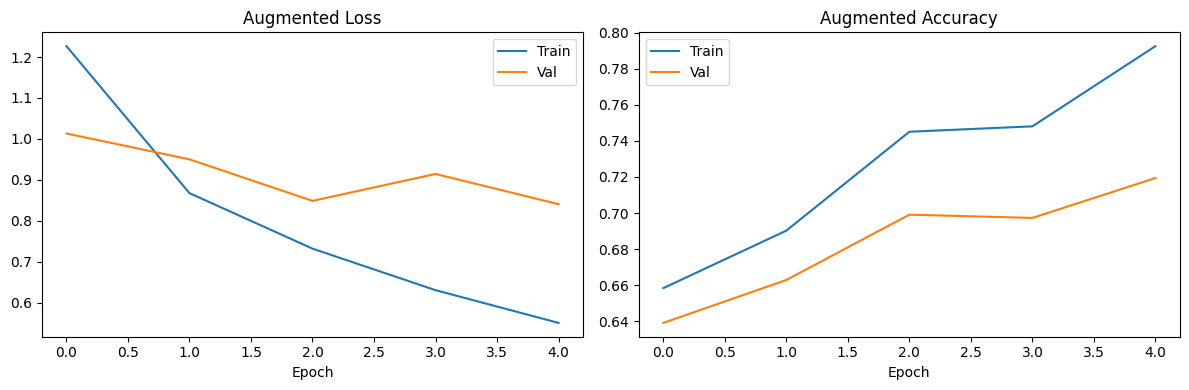

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses_aug, label='Train')
ax1.plot(val_losses_aug, label='Val')
ax1.set_title('Augmented Loss')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(train_accs_aug, label='Train')
ax2.plot(val_accs_aug, label='Val')
ax2.set_title('Augmented Accuracy')
ax2.set_xlabel('Epoch')
ax2.legend()

plt.tight_layout()
plt.show()

In [21]:
print(f"Part A (no aug) final val acc: {val_accs[-1]:.1%}")
print(f"Part B (aug)    final val acc: {val_accs_aug[-1]:.1%}")
print(f"Part A training time: {elapsed:.1f}s")
print(f"Part B training time: {elapsed_aug:.1f}s")

Part A (no aug) final val acc: 65.9%
Part B (aug)    final val acc: 71.9%
Part A training time: 551.2s
Part B training time: 552.8s


# PART C

In [22]:
mobilenet_transform = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [23]:
torch.manual_seed(42)

full_train_tl = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=mobilenet_transform
)

train_data_tl, val_data_tl = random_split(full_train_tl, [train_size, val_size])

train_loader_tl = DataLoader(train_data_tl, batch_size=64, shuffle=True)
val_loader_tl   = DataLoader(val_data_tl,   batch_size=64, shuffle=False)

print(f"Transfer learning train: {len(train_data_tl)}, Val: {len(val_data_tl)}")

Transfer learning train: 40000, Val: 10000


In [24]:
model_tl = models.mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)
for param in model_tl.features.parameters():
    param.requires_grad = False
in_features = model_tl.classifier[1].in_features
model_tl.classifier[1] = nn.Linear(in_features, 10)
model_tl = model_tl.to(device)

optimizer_tl = torch.optim.Adam(model_tl.parameters(), lr=0.001)

In [25]:
epochs = 3
train_losses_tl, val_losses_tl = [], []
train_accs_tl, val_accs_tl = [], []

start = time.time()

for epoch in range(epochs):
    model_tl.train()
    model_tl.features.eval()
    total_loss = 0
    for X_batch, y_batch in train_loader_tl:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        logits = model_tl(X_batch)
        loss = loss_fn(logits, y_batch)
        optimizer_tl.zero_grad()
        loss.backward()
        optimizer_tl.step()
        total_loss += loss.item()

    train_losses_tl.append(total_loss / len(train_loader_tl))
    val_loss, val_acc = get_loss_and_acc(model_tl, val_loader_tl)
    train_acc = get_loss_and_acc(model_tl, train_loader_tl)[1]

    val_losses_tl.append(val_loss)
    train_accs_tl.append(train_acc)
    val_accs_tl.append(val_acc)

    print(f"Epoch {epoch+1}: train loss={train_losses_tl[-1]:.4f}, val loss={val_loss:.4f}, "
          f"train acc={train_acc:.1%}, val acc={val_acc:.1%}")

elapsed_tl = time.time() - start
print(f"\nTransfer learning training time: {elapsed_tl:.1f} seconds")

Epoch 1: train loss=0.5447, val loss=0.3956, train acc=87.3%, val acc=86.4%
Epoch 2: train loss=0.3866, val loss=0.3646, train acc=89.0%, val acc=87.3%
Epoch 3: train loss=0.3610, val loss=0.3577, train acc=89.5%, val acc=87.4%

Transfer learning training time: 5956.7 seconds


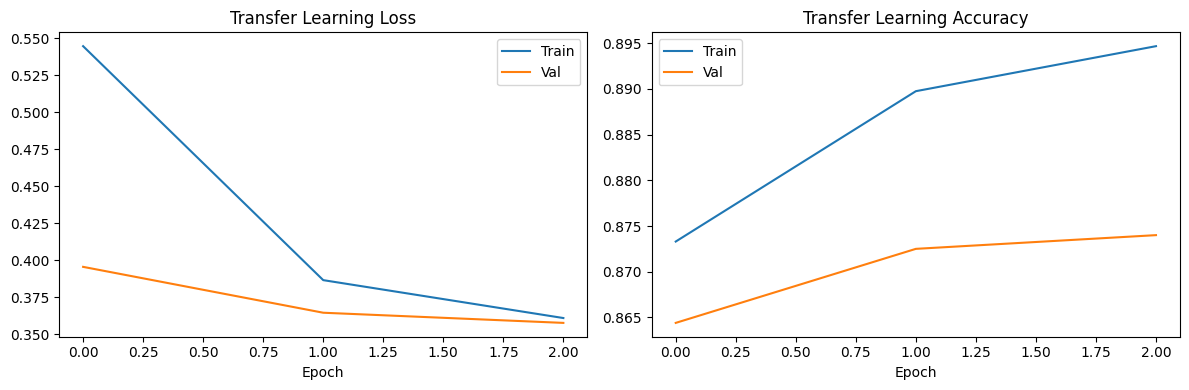

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses_tl, label='Train')
ax1.plot(val_losses_tl, label='Val')
ax1.set_title('Transfer Learning Loss')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(train_accs_tl, label='Train')
ax2.plot(val_accs_tl, label='Val')
ax2.set_title('Transfer Learning Accuracy')
ax2.set_xlabel('Epoch')
ax2.legend()

plt.tight_layout()
plt.show()

In [27]:
print(f"Part A (CNN, no aug)     val acc: {val_accs[-1]:.1%}   time: {elapsed:.1f}s")
print(f"Part B (CNN + aug)       val acc: {val_accs_aug[-1]:.1%}   time: {elapsed_aug:.1f}s")
print(f"Part C (MobileNetV2)     val acc: {val_accs_tl[-1]:.1%}   time: {elapsed_tl:.1f}s")

Part A (CNN, no aug)     val acc: 65.9%   time: 551.2s
Part B (CNN + aug)       val acc: 71.9%   time: 552.8s
Part C (MobileNetV2)     val acc: 87.4%   time: 5956.7s


# RUN ON TEST (parts A, B, and C final models)

In [28]:
# Part A (non-augmented CNN)
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        logits = model(X_batch)
        preds = logits.argmax(dim=1)
        y_true.extend(y_batch.numpy())
        y_pred.extend(preds.cpu().numpy())
test_acc_a = (torch.tensor(y_true) == torch.tensor(y_pred)).float().mean().item()

# Part B (augmented CNN)
model_aug.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        logits = model_aug(X_batch)
        preds = logits.argmax(dim=1)
        y_true.extend(y_batch.numpy())
        y_pred.extend(preds.cpu().numpy())
test_acc_b = (torch.tensor(y_true) == torch.tensor(y_pred)).float().mean().item()

# Part C (MobileNetV2) — needs the resized/normalized test set
test_data_tl = datasets.CIFAR10(root="data", train=False, download=True, transform=mobilenet_transform)
test_loader_tl = DataLoader(test_data_tl, batch_size=64, shuffle=False)

model_tl.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for X_batch, y_batch in test_loader_tl:
        X_batch = X_batch.to(device)
        logits = model_tl(X_batch)
        preds = logits.argmax(dim=1)
        y_true.extend(y_batch.numpy())
        y_pred.extend(preds.cpu().numpy())
test_acc_c = (torch.tensor(y_true) == torch.tensor(y_pred)).float().mean().item()

print(f"Part A test accuracy: {test_acc_a:.1%}")
print(f"Part B test accuracy: {test_acc_b:.1%}")
print(f"Part C test accuracy: {test_acc_c:.1%}")

Part A test accuracy: 65.4%
Part B test accuracy: 71.8%
Part C test accuracy: 87.1%
